# mmg_toolbox example
## Peak Fitting using ROIs
This short notebook describes how to perform multi-peak fitting on a sequence of scans

### *Notebook Notes*
This notebook will run with any modern version of python and requires *mmg_toolbox*, which can be installed easily using:
```bash
python -m pip install mmg_toolbox
```

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from mmg_toolbox import Experiment

## Example data

From R. Scatena

Location: `/dls/science/groups/das/ExampleData/i16/temp_dep`

### mm42963-2
- range(1160565, 1160717, 4)  # mag1 LH
- range(1160566, 1160717, 4)  # mag1 C1
- range(1160567, 1160717, 4)  # mag1 LV
- range(1160568, 1160717, 4)  # mag1 L2


In [2]:
folder = '/dls/science/groups/das/ExampleData/i16/temp_dep'
exp = Experiment(folder, instrument='i16')

print(exp)

Instrument: i16
/dls/science/groups/das/ExampleData/i16/temp_dep
    Files: 153
    Scans: 1160565-1160717


## Defining Regions of Interest (ROIs)

In [12]:
# Current/ default ROIs (from default config for i16)
print(exp.config['roi'])

# ROI defined as ('name', 'centre_i', 'centre_j', 'width_i', 'width_j', 'detector name')

[('pilroi1', 'pil3_centre_j', 'pil3_centre_i', 30, 30, 'pil3_100k')]


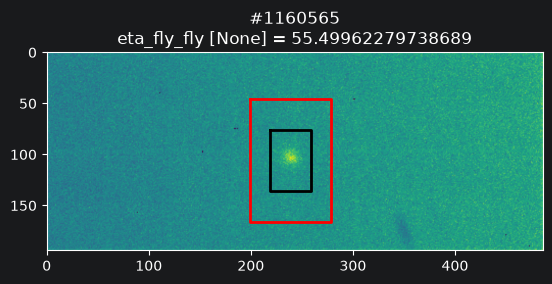

In [27]:
# Define ROIs
# this must be done prior to loading data to propagate ROIs from exp object to scan object
# indexes can be int or string expressions, allowing to access the stored central pixel
exp.add_roi('new_roi', cen_i='pil3_centre_j', cen_j='pil3_centre_i', wid_i=60, wid_j=40, image_name='pil3_100k')

scan = exp.scan(1160565)

# Create plot of image
ax = scan.plot.image()
# add box for ROI
box = scan('new_roi_box')  # box lines
bkg = scan('new_roi_bkg_box')
ax.plot(box[:, 1], box[:, 0], color='k', linewidth=2)
ax.plot(bkg[:, 1], bkg[:, 0], color='r', linewidth=2)



(81, 60, 40)


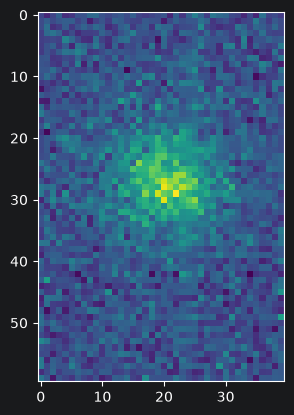

In [24]:
# Access the array of the roi
roi = scan('new_roi')
print(roi.shape)
fig, ax2 = plt.subplots()
ax2.imshow(roi[40, :, :])

In [28]:
print(scan.info(alternate=True))


Scannables Namespace:
                   eta_fly_fly: (81,)      : /entry/measurement/eta_fly_fly                              
                 BeamOk_beamok: (81,)      : /entry/instrument/BeamOk/BeamOk_beamok                      
wait_for_injection_scan_start_beamok: (81,)      : /entry/instrument/wait_for_injection_scan_start/wait_for_injection_scan_start_beamok
wait_for_beam_scan_start_beamok: (81,)      : /entry/instrument/wait_for_beam_scan_start/wait_for_beam_scan_start_beamok
                      roi2_max: (81,)      : /entry/instrument/roi2/roi2_max                             
                      roi2_sum: (81,)      : /entry/instrument/roi2/roi2_sum                             
                      roi1_max: (81,)      : /entry/instrument/roi1/roi1_max                             
                      roi1_sum: (81,)      : /entry/instrument/roi1/roi1_sum                             
                         kphi_: (81,)      : /entry/instrument/showkap6/kphi_       

Text(0, 0.5, 'new_roi_total')

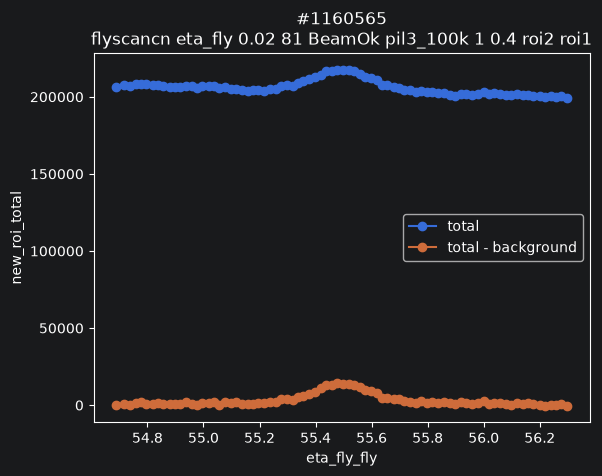

In [29]:
# Plotting integrated data from an ROI
fig, ax = plt.subplots()
scan.plot('axes', 'new_roi_total', axes=ax, label='total')
scan.plot('axes', 'new_roi_rmbkg', axes=ax, label='total - background')
ax.legend()
ax.set_xlabel(scan.replace_default_names('axes'))
ax.set_ylabel('new_roi_total')

## Fitting a Temperature Dependence

In [31]:
# Load data
lh_scans = exp.scans(*range(1160565, 1160717, 4))
c1_scans = exp.scans(*range(1160566, 1160717, 4))
lv_scans = exp.scans(*range(1160567, 1160717, 4))
c2_scans = exp.scans(*range(1160568, 1160717, 4))

<Axes: title={'center': 'temp_dep 1160[565:4:713] \nflyscancn eta_fly 0.02 81 BeamOk pil3_100k 1 0.4 roi2 roi1'}, xlabel='eta_fly_fly', ylabel='roi1_sum'>

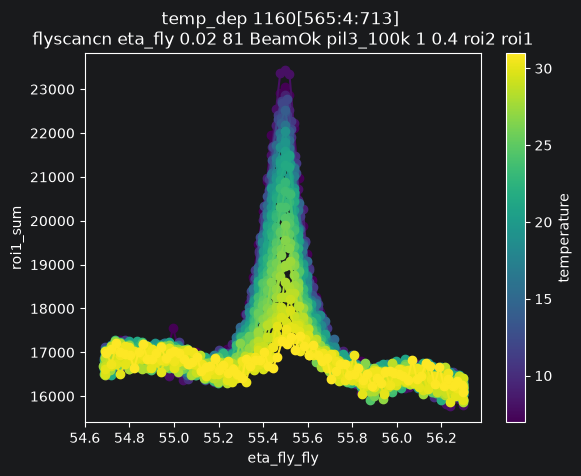

In [7]:
# Plot data
exp.plot.multi_lines(*lh_scans, xaxis='axes', yaxis='signal', value='Tsample')

Fitting with 1 peaks
#1160565
Fit Results
(Model(linear, prefix='bkg_') + Model(gaussian, prefix='p1_'))
Npeaks = 1
Method: leastsq => Fit succeeded.
Chisqr = 36989

Peak p1_
   p1_amplitude = 3800 (200)
      p1_center = 55.494 (7)
       p1_sigma = 0.122 (6)
        p1_fwhm = 0.29 (1)
      p1_height = 1.23(8)E+4

Background
      bkg_slope = 0 (100)
  bkg_intercept = -2000 (6000)

Totals
      amplitude = 3800 (200)
         center = 55.494 (7)
         height = 1.23(8)E+4
          sigma = 0.122 (6)
           fwhm = 0.29 (1)
     background = 390 (20)

1160565: 6.95K amplitude=3787.99, centre=55.49, width=0.29


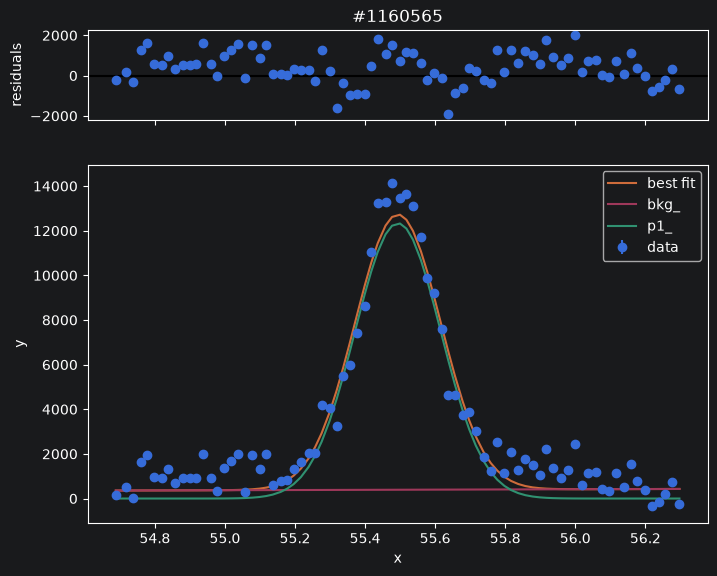

In [40]:
# Test fit parameters on a single scan
scan = lh_scans[0]

scan.fit.multi_peak_fit(xaxis='axes', yaxis='new_roi_rmbkg', plot_result=True, print_result=True, npeaks=1)

print(scan.format('{scan_number}: {Tsample:.2f}K amplitude={amplitude:.2f}, centre={center:.2f}, width={fwhm:.2f}'))

In [48]:
# Perform fits
for scan in lh_scans:
    scan.fit.multi_peak_fit(xaxis='axes', yaxis='new_roi_rmbkg', npeaks=2, min_peak_power=1)
    print(scan.format('{scan_number}: {Tsample:.2f}K amplitude={amplitude:.2f}, centre={center:.2f}, width={fwhm:.2f}'))

Fitting with 2 peaks
1160565: 6.95K amplitude=4189.65, centre=55.70, width=0.29
Fitting with 2 peaks
1160569: 7.97K amplitude=4030.92, centre=55.66, width=0.28
Fitting with 2 peaks
1160573: 8.98K amplitude=4011.01, centre=55.71, width=0.28
Fitting with 2 peaks
1160577: 10.00K amplitude=3836.02, centre=55.29, width=0.25
Fitting with 2 peaks
1160581: 10.98K amplitude=3806.23, centre=55.26, width=0.22
Fitting with 2 peaks
Refitting with 1 peaks
1160585: 11.96K amplitude=3235.39, centre=55.49, width=0.25
Fitting with 2 peaks
Refitting with 1 peaks
1160589: 12.96K amplitude=3330.37, centre=55.50, width=0.27
Fitting with 2 peaks
Refitting with 1 peaks
1160593: 13.96K amplitude=3219.73, centre=55.49, width=0.28
Fitting with 2 peaks
1160597: 14.99K amplitude=3805.03, centre=55.22, width=0.24
Fitting with 2 peaks
Refitting with 1 peaks
1160601: 15.97K amplitude=3093.68, centre=55.51, width=0.27
Fitting with 2 peaks
1160605: 16.99K amplitude=3202.85, centre=55.27, width=0.24
Fitting with 2 peaks

/scratch/grp66007/python/mmg_toolbox/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:3862: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
/scratch/grp66007/python/mmg_toolbox/.venv/lib/python3.14/site-packages/numpy/_core/_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Fitting with 2 peaks
1160713: 31.00K amplitude=1287.09, centre=55.35, width=0.45


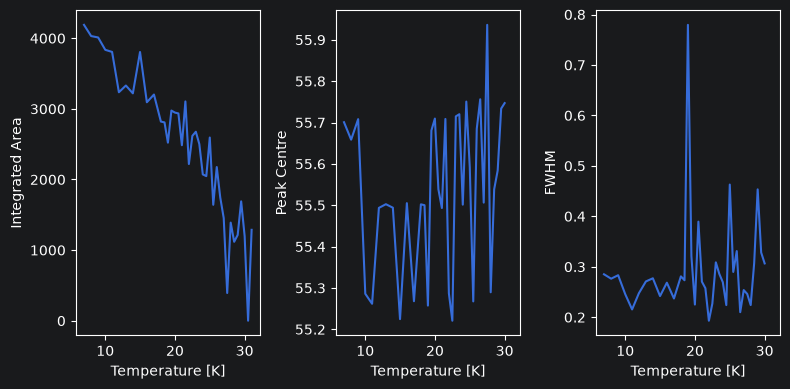

In [49]:
# Plot results
temperature, area, cen, fwhm = exp.join_scan_arrays(*lh_scans, data_fields=['Tsample', 'amplitude', 'center', 'fwhm'])

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=[8, 4])
ax1.plot(temperature, area)
ax2.plot(temperature, cen)
ax3.plot(temperature, fwhm)
ax1.set_xlabel('Temperature [K]')
ax2.set_xlabel('Temperature [K]')
ax3.set_xlabel('Temperature [K]')
ax1.set_ylabel('Integrated Area')
ax2.set_ylabel('Peak Centre')
ax3.set_ylabel('FWHM')
fig.tight_layout()